In [1]:
import pandas as pd

df = pd.read_csv("../data/dataset_estudiantes.csv")
print(df.shape)
display(df.head())
df.info()
display(df.describe(include="all").T)
print("Nulos:\n", df.isna().sum())
print("Duplicados:", df.duplicated().sum())


(1000, 11)


,horas_estudio_semanal,nota_anterior,tasa_asistencia,horas_sueno,edad,nivel_dificultad,tiene_tutor,horario_estudio_preferido,estilo_aprendizaje,nota_final,aprobado
0,8.957476,48.830601,86.640182,6.675694,25,Fácil,Sí,Tarde,Lectura/Escritura,84.4,1
1,11.042524,80.825707,83.449655,4.616844,18,Difícil,No,Tarde,NaN,72.0,1
2,4.510776,90.383694,74.623607,7.755246,25,Fácil,No,Mañana,Lectura/Escritura,80.0,1
3,6.647213,81.878257,82.849841,8.592826,23,Fácil,No,NaN,Visual,78.2,1
4,1.000000,66.254179,54.539935,6.671840,21,Medio,No,NaN,Auditivo,66.0,1


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   horas_estudio_semanal      1000 non-null   float64
 1   nota_anterior              1000 non-null   float64
 2   tasa_asistencia            1000 non-null   float64
 3   horas_sueno                850 non-null    float64
 4   edad                       1000 non-null   int64  
 5   nivel_dificultad           1000 non-null   str    
 6   tiene_tutor                1000 non-null   str    
 7   horario_estudio_preferido  900 non-null    str    
 8   estilo_aprendizaje         950 non-null    str    
 9   nota_final                 1000 non-null   float64
 10  aprobado                   1000 non-null   int64  
dtypes: float64(5), int64(2), str(4)
memory usage: 86.1 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
horas_estudio_semanal,1000.0,NaN,NaN,NaN,10.072366,4.852218,1.0,6.627548,10.0,13.372452,25.0
nota_anterior,1000.0,NaN,NaN,NaN,69.885456,14.687697,30.0,59.882644,70.0,80.117356,100.0
tasa_asistencia,1000.0,NaN,NaN,NaN,73.992079,18.195948,20.0,61.510192,75.0,88.489808,100.0
horas_sueno,850.0,NaN,NaN,NaN,7.00767,1.44479,4.0,5.995341,7.020701,8.018834,10.0
edad,1000.0,NaN,NaN,NaN,23.532,3.476933,18.0,21.0,24.0,27.0,29.0
nivel_dificultad,1000,3,Medio,504,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tiene_tutor,1000,2,No,597,NaN,NaN,NaN,NaN,NaN,NaN,NaN
horario_estudio_preferido,900,3,Noche,344,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estilo_aprendizaje,950,4,Visual,363,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nota_final,1000.0,NaN,NaN,NaN,71.4414,9.562078,30.0,64.775,71.4,77.9,100.0


Nulos:
 horas_estudio_semanal          0
nota_anterior                  0
tasa_asistencia                0
horas_sueno                  150
edad                           0
nivel_dificultad               0
tiene_tutor                    0
horario_estudio_preferido    100
estilo_aprendizaje            50
nota_final                     0
aprobado                       0
dtype: int64
Duplicados: 0


## 1. Análisis exploratorio (EDA)

Nota mínima de los aprobados: 60.0
Nota máxima de los suspensos: 59.9


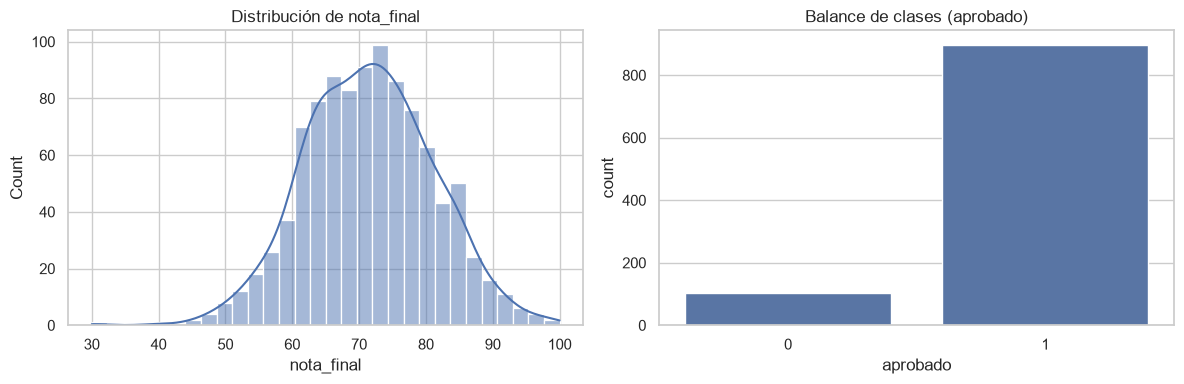

aprobado
1    0.898
0    0.102
Name: proportion, dtype: float64


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1) Relación entre los dos targets: ¿aprobado sale de nota_final?
print("Nota mínima de los aprobados:", df.loc[df.aprobado == 1, "nota_final"].min())
print("Nota máxima de los suspensos:", df.loc[df.aprobado == 0, "nota_final"].max())

# 2) Distribución de los targets
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["nota_final"], bins=30, kde=True, ax=ax[0])
ax[0].set_title("Distribución de nota_final")
sns.countplot(x="aprobado", data=df, ax=ax[1])
ax[1].set_title("Balance de clases (aprobado)")
plt.tight_layout()
plt.show()

print(df["aprobado"].value_counts(normalize=True))


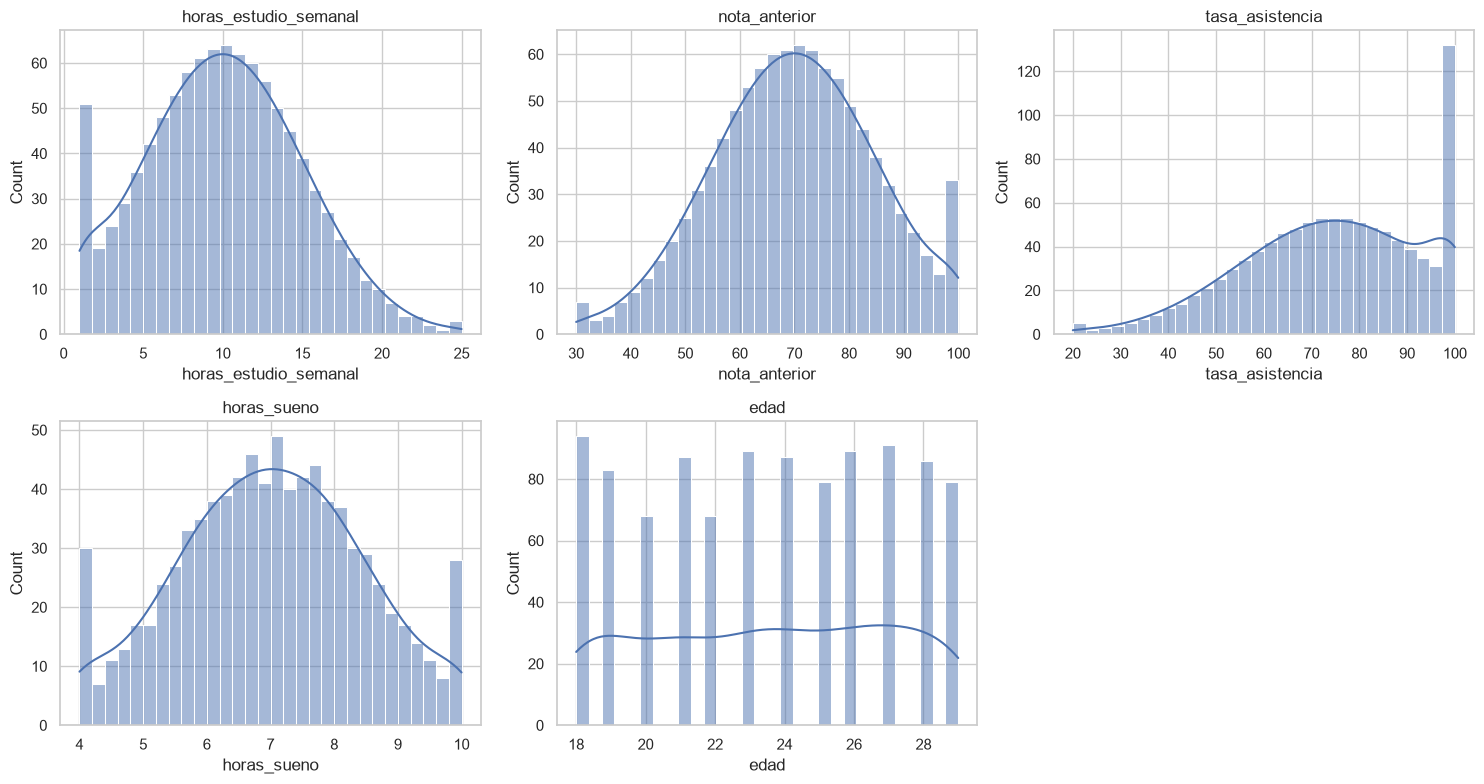

horas_estudio_semanal: 36 en el mínimo, 2 en el máximo
nota_anterior: 4 en el mínimo, 23 en el máximo
tasa_asistencia: 3 en el mínimo, 106 en el máximo
horas_sueno: 22 en el mínimo, 20 en el máximo


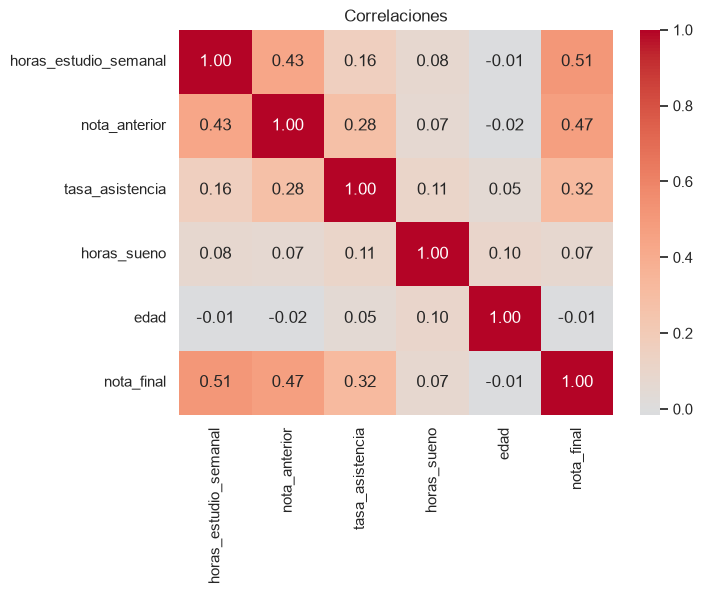

In [3]:
num_cols = ["horas_estudio_semanal", "nota_anterior", "tasa_asistencia", "horas_sueno", "edad"]

# 1) Distribución de cada predictor numérico
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

# 2) ¿Cuántos valores están pegados a los topes (recorte)?
for col in ["horas_estudio_semanal", "nota_anterior", "tasa_asistencia", "horas_sueno"]:
    print(f"{col}: {(df[col] == df[col].min()).sum()} en el mínimo, "
          f"{(df[col] == df[col].max()).sum()} en el máximo")

# 3) Correlación con el target de regresión
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols + ["nota_final"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlaciones")
plt.show()


In [4]:
cat_cols = ["nivel_dificultad", "tiene_tutor", "horario_estudio_preferido", "estilo_aprendizaje"]

# 1) Nota media y % de aprobados por categoría (los NaN se muestran como una categoría más)
for col in cat_cols:
    print(f"\n--- {col} ---")
    print(df.groupby(col, dropna=False).agg(
        n=("nota_final", "size"),
        nota_media=("nota_final", "mean"),
        pct_aprobado=("aprobado", "mean"),
    ).round(2))

# 2) ¿Los nulos son aleatorios? Comparo la nota de quien tiene dato y de quien no
for col in ["horas_sueno", "horario_estudio_preferido", "estilo_aprendizaje"]:
    print(f"\n{col}: nota media con dato = {df.loc[df[col].notna(), 'nota_final'].mean():.2f}, "
          f"sin dato = {df.loc[df[col].isna(), 'nota_final'].mean():.2f}")



--- nivel_dificultad ---
                    n  nota_media  pct_aprobado
nivel_dificultad                               
Difícil           183       69.48          0.85
Fácil             313       72.50          0.92
Medio             504       71.49          0.90

--- tiene_tutor ---
               n  nota_media  pct_aprobado
tiene_tutor                               
No           597       68.84          0.86
Sí           403       75.29          0.96

--- horario_estudio_preferido ---
                             n  nota_media  pct_aprobado
horario_estudio_preferido                               
Mañana                     219       71.60          0.91
Noche                      344       70.81          0.87
Tarde                      337       71.71          0.91
NaN                        100       72.37          0.95

--- estilo_aprendizaje ---
                      n  nota_media  pct_aprobado
estilo_aprendizaje                               
Auditivo            254       71.82 

## 2. Preprocesamiento

In [5]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42  # semilla fija: el reparto es siempre el mismo (reproducible)

# Predictores: quitamos ambos targets para evitar fuga de datos
X = df.drop(columns=["nota_final", "aprobado"])
y_reg = df["nota_final"]   # target de regresión
y_clf = df["aprobado"]     # target de clasificación

# 80 % entrenamiento / 20 % test. Un único split para los dos problemas,
# así comparamos regresión y clasificación sobre los mismos alumnos.
# stratify=y_clf mantiene el ~10 % de suspensos en train y en test.
X_train, X_test, y_reg_train, y_reg_test, y_clf_train, y_clf_test = train_test_split(
    X, y_reg, y_clf, test_size=0.2, stratify=y_clf, random_state=RANDOM_STATE
)

print(X_train.shape, X_test.shape)
print("% suspensos train:", round(1 - y_clf_train.mean(), 3), "| test:", round(1 - y_clf_test.mean(), 3))


(800, 9) (200, 9)
% suspensos train: 0.103 | test: 0.1


In [6]:
# Cada grupo recibe un tratamiento distinto en el preprocesador
num_cols = ["horas_estudio_semanal", "nota_anterior", "tasa_asistencia", "horas_sueno", "edad"]  # imputar mediana + escalar
ord_cols = ["nivel_dificultad"]                                 # categórica con orden: Fácil < Medio < Difícil
bin_cols = ["tiene_tutor"]                                      # binaria: Sí/No -> 1 columna 0/1
nom_cols = ["horario_estudio_preferido", "estilo_aprendizaje"]  # nominales con nulos: "Desconocido" + one-hot

# Comprobación: no debe faltar ni sobrar ninguna columna
todas = num_cols + ord_cols + bin_cols + nom_cols
print(len(todas), "columnas agrupadas")
print("Columnas de X sin asignar:", set(X.columns) - set(todas))


9 columnas agrupadas
Columnas de X sin asignar: set()


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder

# Numéricas: rellenar nulos con la mediana (robusta) y escalar (media 0, desviación 1)
pipe_num = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Nominales: los nulos pasan a ser una categoría propia y luego one-hot
pipe_nom = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Desconocido")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),  # ignore: no falla si aparece una categoría nueva
])

# Une cada tratamiento con su grupo de columnas
preprocesador = ColumnTransformer([
    ("num", pipe_num, num_cols),
    ("ord", OrdinalEncoder(categories=[["Fácil", "Medio", "Difícil"]]), ord_cols),  # orden explícito
    ("bin", OneHotEncoder(drop="if_binary"), bin_cols),  # Sí/No -> una sola columna 0/1
    ("nom", pipe_nom, nom_cols),
])


In [8]:
# fit solo con TRAIN: medianas y medias se calculan sin mirar el test (evita fuga de datos)
preprocesador.fit(X_train)

X_train_proc = preprocesador.transform(X_train)
print("Forma tras el preproceso:", X_train_proc.shape)
print(list(preprocesador.get_feature_names_out()))
print("Nulos restantes:", pd.DataFrame(X_train_proc.toarray() if hasattr(X_train_proc, "toarray") else X_train_proc).isna().sum().sum())


Forma tras el preproceso: (800, 16)
['num__horas_estudio_semanal', 'num__nota_anterior', 'num__tasa_asistencia', 'num__horas_sueno', 'num__edad', 'ord__nivel_dificultad', 'bin__tiene_tutor_Sí', 'nom__horario_estudio_preferido_Desconocido', 'nom__horario_estudio_preferido_Mañana', 'nom__horario_estudio_preferido_Noche', 'nom__horario_estudio_preferido_Tarde', 'nom__estilo_aprendizaje_Auditivo', 'nom__estilo_aprendizaje_Desconocido', 'nom__estilo_aprendizaje_Kinestésico', 'nom__estilo_aprendizaje_Lectura/Escritura', 'nom__estilo_aprendizaje_Visual']
Nulos restantes: 0


## 3. Modelo de regresión (nota_final)

In [9]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_val_score

# Validación cruzada: 5 partes de train, se entrena con 4 y se mide con la 5ª
cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Línea base: siempre predice la media de nota_final
base = Pipeline([("prep", preprocesador), ("modelo", DummyRegressor(strategy="mean"))])

# MAE = error medio en puntos de nota (sklearn lo devuelve en negativo, por eso el signo -)
mae = -cross_val_score(base, X_train, y_reg_train, cv=cv_reg, scoring="neg_mean_absolute_error")
print("MAE línea base:", mae.mean().round(2))


MAE línea base: 7.61


In [10]:
from sklearn.linear_model import LinearRegression

# Mismo pipeline, pero con un modelo que sí aprende de las variables
lineal = Pipeline([("prep", preprocesador), ("modelo", LinearRegression())])

mae = -cross_val_score(lineal, X_train, y_reg_train, cv=cv_reg, scoring="neg_mean_absolute_error")
r2 = cross_val_score(lineal, X_train, y_reg_train, cv=cv_reg, scoring="r2")

print("MAE regresión lineal:", mae.mean().round(2))
print("R² regresión lineal:", r2.mean().round(3))


MAE regresión lineal: 6.04
R² regresión lineal: 0.365


In [11]:
from sklearn.ensemble import RandomForestRegressor

# Random Forest: muchos árboles de decisión promediados; captura relaciones no lineales
rf = Pipeline([("prep", preprocesador),
               ("modelo", RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE))])

mae = -cross_val_score(rf, X_train, y_reg_train, cv=cv_reg, scoring="neg_mean_absolute_error")
r2 = cross_val_score(rf, X_train, y_reg_train, cv=cv_reg, scoring="r2")

print("MAE Random Forest:", mae.mean().round(2))
print("R² Random Forest:", r2.mean().round(3))


MAE Random Forest: 6.33
R² Random Forest: 0.314


In [12]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Entrenamos el modelo elegido con TODO el train y predecimos el test
lineal.fit(X_train, y_reg_train)
pred_test = lineal.predict(X_test)

print("MAE test:", round(mean_absolute_error(y_reg_test, pred_test), 2))
print("RMSE test:", round(root_mean_squared_error(y_reg_test, pred_test), 2))
print("R² test:", round(r2_score(y_reg_test, pred_test), 3))


MAE test: 6.12
RMSE test: 7.45
R² test: 0.395


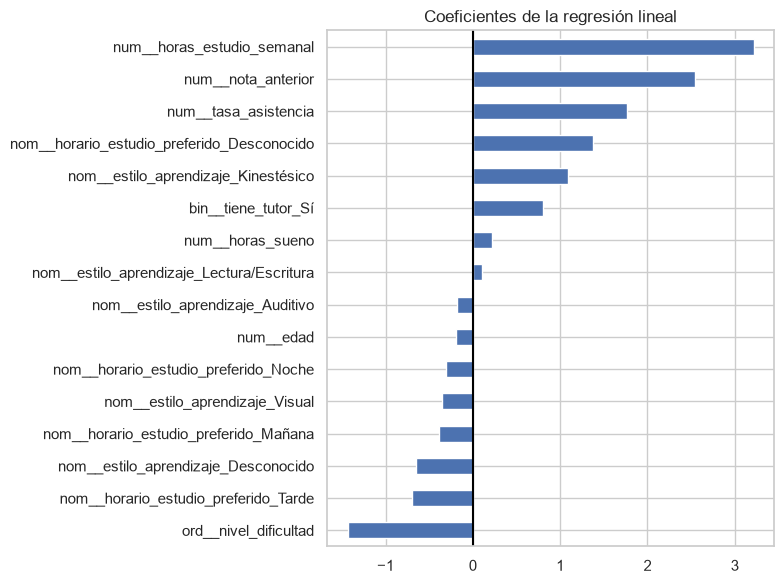

In [13]:
# Coeficientes del modelo (las numéricas están escaladas: comparables entre sí)
coefs = pd.Series(
    lineal.named_steps["modelo"].coef_,
    index=lineal.named_steps["prep"].get_feature_names_out(),
).sort_values()

coefs.plot(kind="barh", figsize=(8, 6), title="Coeficientes de la regresión lineal")
plt.axvline(0, color="black")
plt.tight_layout()
plt.show()


In [14]:
# ¿Los alumnos con tutor estudian y asisten más? (explicaría el cambio de efecto)
df.groupby("tiene_tutor")[["horas_estudio_semanal", "tasa_asistencia", "nota_anterior"]].mean().round(1)


,horas_estudio_semanal,tasa_asistencia,nota_anterior
tiene_tutor,,,
No,7.7,72.7,66.8
Sí,13.6,75.9,74.5


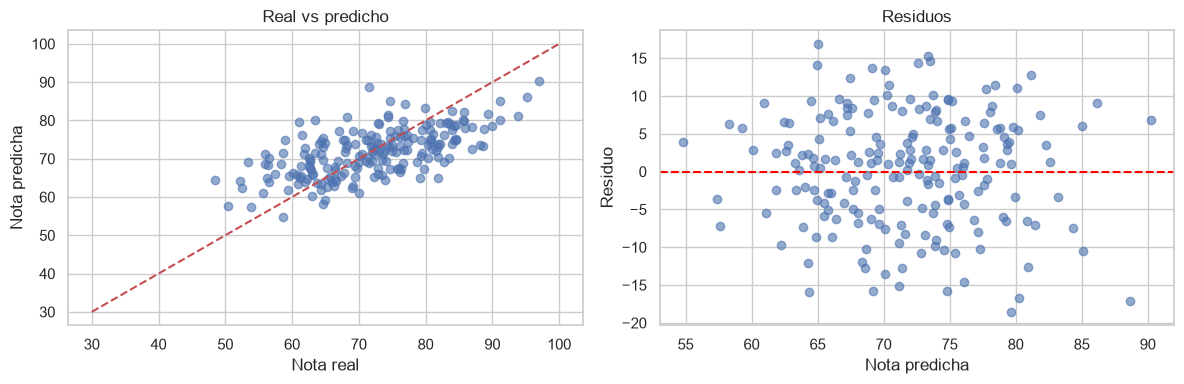

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Real vs predicho: los puntos deberían alinearse con la diagonal
ax[0].scatter(y_reg_test, pred_test, alpha=0.6)
ax[0].plot([30, 100], [30, 100], "r--")  # predicción perfecta
ax[0].set(xlabel="Nota real", ylabel="Nota predicha", title="Real vs predicho")

# Residuos = real - predicho: deberían repartirse alrededor de 0 sin patrón
residuos = y_reg_test - pred_test
ax[1].scatter(pred_test, residuos, alpha=0.6)
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set(xlabel="Nota predicha", ylabel="Residuo", title="Residuos")

plt.tight_layout()
plt.show()


## 4. Modelo de clasificación (aprobado).

In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

# CV estratificada: cada fold conserva el ~10 % de suspensos
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Línea base: siempre predice la clase mayoritaria (aprobado)
base_clf = Pipeline([("prep", preprocesador), ("modelo", DummyClassifier(strategy="most_frequent"))])

# accuracy = % de aciertos; balanced_accuracy = media del acierto en cada clase (no se deja engañar por el desbalance)
for metrica in ["accuracy", "balanced_accuracy"]:
    puntuacion = cross_val_score(base_clf, X_train, y_clf_train, cv=cv_clf, scoring=metrica)
    print(f"{metrica} línea base:", puntuacion.mean().round(3))


accuracy línea base: 0.898
balanced_accuracy línea base: 0.5


In [17]:
from sklearn.linear_model import LogisticRegression

# class_weight="balanced": da más peso a los suspensos para compensar que son solo el 10 %
logistica = Pipeline([("prep", preprocesador),
                      ("modelo", LogisticRegression(class_weight="balanced", max_iter=1000))])

# Con pos_label=0, las métricas se calculan para la clase "suspenso"
from sklearn.metrics import make_scorer, recall_score, f1_score
scoring = {
    "bal_acc": "balanced_accuracy",
    "recall_susp": make_scorer(recall_score, pos_label=0),
    "f1_susp": make_scorer(f1_score, pos_label=0),
}

from sklearn.model_selection import cross_validate
r = cross_validate(logistica, X_train, y_clf_train, cv=cv_clf, scoring=scoring)
for nombre in scoring:
    print(nombre, r[f"test_{nombre}"].mean().round(3))


bal_acc 0.725
recall_susp 0.693
f1_susp 0.362


In [18]:
from sklearn.ensemble import RandomForestClassifier

# Mismo criterio: class_weight="balanced" para no ignorar la clase minoritaria
rf_clf = Pipeline([("prep", preprocesador),
                   ("modelo", RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                                     random_state=RANDOM_STATE))])

r = cross_validate(rf_clf, X_train, y_clf_train, cv=cv_clf, scoring=scoring)
for nombre in scoring:
    print(nombre, r[f"test_{nombre}"].mean().round(3))


bal_acc 0.636
recall_susp 0.315
f1_susp 0.371


              precision    recall  f1-score   support

    Suspenso       0.20      0.65      0.31        20
    Aprobado       0.95      0.72      0.82       180

    accuracy                           0.71       200
   macro avg       0.58      0.68      0.56       200
weighted avg       0.87      0.71      0.77       200



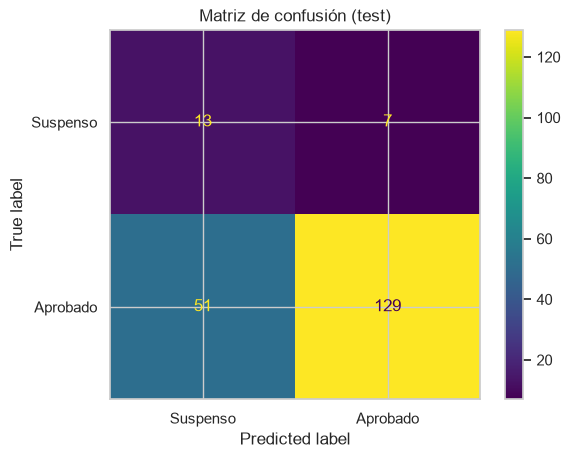

In [19]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Entrenamos con todo el train y predecimos el test
logistica.fit(X_train, y_clf_train)
pred_clf = logistica.predict(X_test)

# Informe por clase: precisión, recall y F1 de suspensos (0) y aprobados (1)
print(classification_report(y_clf_test, pred_clf, target_names=["Suspenso", "Aprobado"]))

# Matriz de confusión: filas = realidad, columnas = predicción
ConfusionMatrixDisplay.from_predictions(y_clf_test, pred_clf, display_labels=["Suspenso", "Aprobado"])
plt.title("Matriz de confusión (test)")
plt.show()


In [20]:
from sklearn.metrics import roc_auc_score

# Probabilidad de aprobar de cada alumno del test
proba_aprobar = logistica.predict_proba(X_test)[:, 1]
print("ROC-AUC logística (test):", round(roc_auc_score(y_clf_test, proba_aprobar), 3))

# Mismo cálculo para el Random Forest, entrenado con el mismo train
rf_clf.fit(X_train, y_clf_train)
print("ROC-AUC Random Forest (test):", round(roc_auc_score(y_clf_test, rf_clf.predict_proba(X_test)[:, 1]), 3))


ROC-AUC logística (test): 0.815
ROC-AUC Random Forest (test): 0.75
